In [9]:
# Importing Important Libraries
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

## **Exploratory Data Analysis**

In [10]:
# Loading The Dataset Using Pathlib
DATA_PATH = Path("customer_reviews_sentiment_practice.csv")
df = pd.read_csv(DATA_PATH)

# Keep the original data unchanged
data = df.copy()

print("Dataset loaded successfully!")
print("Shape:", data.shape)
data.head()

Dataset loaded successfully!
Shape: (600, 10)


,review_id,customer_id,review_date,product_category,product_name,rating,review_title,review_text,sentiment,verified_purchase
0,REV0001,C1174,2025-04-15,Electronics,Smart Watch,4,Issue with product,Customer support solved my issue quickly. Very...,positive,Yes
1,REV0002,C1007,2026-09-09,Beauty,Face Moisturizer,4,Satisfied,Very happy with this purchase. Delivery was qu...,positive,Yes
2,REV0003,C1088,2026-03-09,Beauty,Face Moisturizer,4,Review,Customer support solved my issue quickly. Very...,positive,Yes
3,REV0004,C1092,2025-04-10,Home,Air Fryer,3,Everyday use,Packaging was fine. I have not used it enough ...,neutral,No
4,REV0005,C1076,2026-07-20,Fashion,Running Shoes,3,Everyday use,It does the basic job without any extra benefits.,neutral,No


- From The Above Dataset We Can See That There Is A Column Name Sentiment And We Have To Predict That Columne Based on The User's Review Text.
- We Will Train The Model On This Model And Test It With The Remaining Data.
- The Original Data Is Preserved and a separate copy is Used For Analysis

In [11]:
# Inspecting And Exploring The Dataset
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

# Number Of Columns Names
print("\nColumn names:")
print(data.columns.tolist())

# Checking The Datatypes Of Each Columns
print("\nData types:")
print(data.dtypes)

Number of rows: 600
Number of columns: 10

Column names:
['review_id', 'customer_id', 'review_date', 'product_category', 'product_name', 'rating', 'review_title', 'review_text', 'sentiment', 'verified_purchase']

Data types:
review_id            object
customer_id          object
review_date          object
product_category     object
product_name         object
rating                int64
review_title         object
review_text          object
sentiment            object
verified_purchase    object
dtype: object


In [12]:
# Checking If Missing Values Are There Or Not
print("\nMissing values:")
print(data.isnull().sum())

# Checking For Duplicate Values
print("\nDuplicate rows:", data.duplicated().sum())


Missing values:
review_id            0
customer_id          0
review_date          0
product_category     0
product_name         0
rating               0
review_title         0
review_text          0
sentiment            0
verified_purchase    0
dtype: int64

Duplicate rows: 0


- As We Can See That There Are No Missing Values In this Dataset And For Duplicates It Is Same
- So There Is no need for cleaning Missing values Or removing Duplicates.

In [13]:
# Checking The Distribution The Sentiment Column To see The Class Balancing 
print("\nSentiment distribution:")
print(data["sentiment"].value_counts())

# Checking The Lowest And Highest Date Range
print("\nDate range:")
data["review_date"] = pd.to_datetime(data["review_date"], errors="coerce")
print("Start:", data["review_date"].min())
print("End:", data["review_date"].max())


Sentiment distribution:
sentiment
positive    246
negative    196
neutral     127
mixed        31
Name: count, dtype: int64

Date range:
Start: 2025-01-04 00:00:00
End: 2026-10-13 00:00:00


- Classes Are Not Evenly Distributed Their Is an Heavy Weightage Towards Positive And Negative Sentiment compared to Mixed and neutral, If later there is a need for OverSampling Techniques We Will Use it But Now We Will Not Change anything.
- The review date column was converted to datetime format to support date-based analysis. Invalid dates were identified for further inspection.

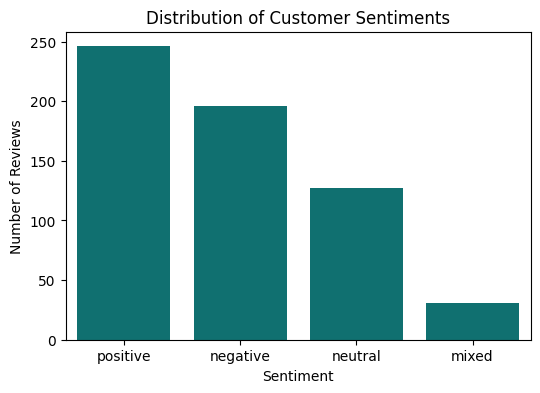

In [14]:
# Summarizing The Customer Feedback Visually
# CountPlot Of Sentiment To Check The Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=data,x="sentiment",order=data["sentiment"].value_counts().index,color="teal")
plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

- This chart shows how customer reviews are distributed across positive, negative, neutral, and mixed sentiments.
- It helps identify the most common customer opinions and whether the dataset has an imbalance between sentiment classes.
- In your dataset, positive reviews are the most frequent, while mixed reviews are the least frequent. The model may therefore have more difficulty learning the mixed category.

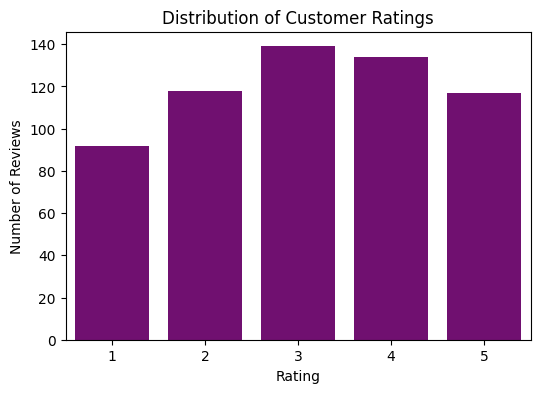

In [15]:
# CountPlot To Check The Ratings Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=data,x="rating",order=sorted(data["rating"].dropna().unique()),color="purple")
plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

- This chart shows how frequently customers give each product rating, from 1 to 5.
- For example, a high number of 1-star ratings could indicate customer dissatisfaction, while a high number of 5-star ratings could suggest positive experiences.